# 📓 Caderno de Exercícios — Aula 05: Visualização de Dados e Storytelling
**Capacitação de Python para Ciência de Dados — Case Campe Supply**

> 💡 **Liberdade Criativa:** Na visualização de dados, você pode usar `seaborn`, `matplotlib` ou até `plotly`! O objetivo não é apenas plotar o gráfico, mas deixá-lo **limpo, com título claro, eixos nomeados e fácil de um diretor bater o olho e tomar uma decisão**.

In [ ]:
"""
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from difflib import get_close_matches

# Configurando o tema visual
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 5)

# === Checkpoint Inicial (Base 100% Limpa das Aulas 01 a 03) ===
df = pd.read_excel('Campe_Supply_Corrompido.xlsx', sheet_name='Campe Supply')
df = df.drop(columns=['UNNAMED: 0', 'coluna_inutil_0', 'coluna_inutil_1'])
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('ã', 'a')
df = df.drop_duplicates().reset_index(drop=True)

categorias_oficiais = {
    'setor': ['Congelados', 'Latícinio', 'Bebidas', 'Carnes'],
    'produto': ['Queijo', 'Sorvete', 'Frango', 'Refrigerantes', 'Cervejas', 'Bovina', 'Leite', 'Lasanha', 'Pizza', 'Suína', 'Sucos', 'Coalhada'],
    'vendedor': ['Vanessa', 'Amaral', 'Leo', 'Daniele', 'Jonas', 'Evandro'],
    'regiao': ['Sudeste', 'Nordeste', 'Sul'],
    'estado': ['Rio de Janeiro', 'Minas Gerais', 'Bahia', 'Rio Grande do Norte', 'São Paulo', 'Sergipe', 'Rio Grande do Sul', 'Paraná', 'Santa Catarina'],
    'cliente': ['Atacarejo', 'Varejo', 'Atacado']
}
def corrigir_palavra(valor, lista_oficial):
    if pd.isna(valor): return np.nan
    match = get_close_matches(str(valor).strip(), lista_oficial, n=1, cutoff=0.6)
    return match[0] if match else np.nan

for col, lista_valida in categorias_oficiais.items():
    df[col] = df[col].apply(lambda x: corrigir_palavra(x, lista_valida))

mapa_produto_setor = {'Queijo': 'Latícinio', 'Leite': 'Latícinio', 'Coalhada': 'Latícinio', 'Sorvete': 'Congelados', 'Lasanha': 'Congelados', 'Pizza': 'Congelados', 'Frango': 'Carnes', 'Bovina': 'Carnes', 'Suína': 'Carnes', 'Refrigerantes': 'Bebidas', 'Cervejas': 'Bebidas', 'Sucos': 'Bebidas'}
mapa_estado_regiao = {'Rio de Janeiro': 'Sudeste', 'Minas Gerais': 'Sudeste', 'São Paulo': 'Sudeste', 'Bahia': 'Nordeste', 'Rio Grande do Norte': 'Nordeste', 'Sergipe': 'Nordeste', 'Rio Grande do Sul': 'Sul', 'Paraná': 'Sul', 'Santa Catarina': 'Sul'}
df['setor'] = df['setor'].fillna(df['produto'].map(mapa_produto_setor))
df['regiao'] = df['regiao'].fillna(df['estado'].map(mapa_estado_regiao))

for col in ['faturamento', 'margem_de_lucro', 'lucro']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.loc[df['lucro'] > df['faturamento'], 'lucro'] = df['faturamento'] * df['margem_de_lucro']
df.loc[(df['margem_de_lucro'] == 0) & (df['lucro'] > 0), 'margem_de_lucro'] = df['lucro'] / df['faturamento']
df.loc[(df['faturamento'] * df['margem_de_lucro'] - df['lucro']).abs() > 0.01, 'faturamento'] = df['lucro'] / df['margem_de_lucro']

df['lucro'] = df['lucro'].fillna(df['faturamento'] * df['margem_de_lucro']).round(2)
df['faturamento'] = df['faturamento'].fillna(df['lucro'] / df['margem_de_lucro']).round(2)
df['margem_de_lucro'] = df['margem_de_lucro'].fillna(df['lucro'] / df['faturamento']).round(2)
df = df.drop_duplicates().reset_index(drop=True)
df['mes'] = df['data_da_venda'].dt.month
"""

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from difflib import get_close_matches

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 5)

arquivo_05 = 'Campe_Supply_Limpo.xlsx'
df = pd.read_excel(arquivo_05)
print(f"Arquivo '{arquivo_05}' carregado com sucesso.")
print(f"Dimensões do DataFrame: {df.shape}")
df.head()

Arquivo 'Campe_Supply_Limpo.xlsx' carregado com sucesso.
Dimensões do DataFrame: (1541, 12)


,data_da_venda,setor,produto,vendedor,regiao,estado,cliente,faturamento,margem_de_lucro,lucro,mes,trimestre
0,2035-01-01,Carnes,Suína,Amaral,Sudeste,Minas Gerais,Atacado,633.45,0.13,82.35,1.0,1.0
1,2035-01-01,Latícinio,Queijo,Leo,Sudeste,Minas Gerais,Atacarejo,611.40,0.07,42.80,1.0,1.0
2,2035-01-01,Congelados,Sorvete,Leo,Nordeste,Não Informado,Atacarejo,721.52,0.08,57.72,1.0,1.0
3,2035-01-01,Carnes,Bovina,Daniele,Sudeste,São Paulo,Atacado,679.39,0.09,61.15,1.0,1.0
4,2035-01-01,Carnes,Frango,Vanessa,Sul,Rio Grande do Sul,Varejo,964.52,0.19,183.26,1.0,1.0


## 🎯 Missão 1: Gráfico de Linha — Sazonalidade Mensal do Faturamento
Agrupe a soma de `faturamento` por `mes` (de 1 a 12) e plote um gráfico de linha (`sns.lineplot` ou `plt.plot`).

* **Dica Visual:** Coloque marcadores nos pontos (`marker='o'`) e renomeie o eixo X com os nomes dos meses (`['Jan', 'Fev', ..., 'Dez']`) usando `plt.xticks()`.
* 🧠 **Insight para descobrir no gráfico:** O que acontece com o faturamento da Campe Supply nos meses de **Novembro e Dezembro**?

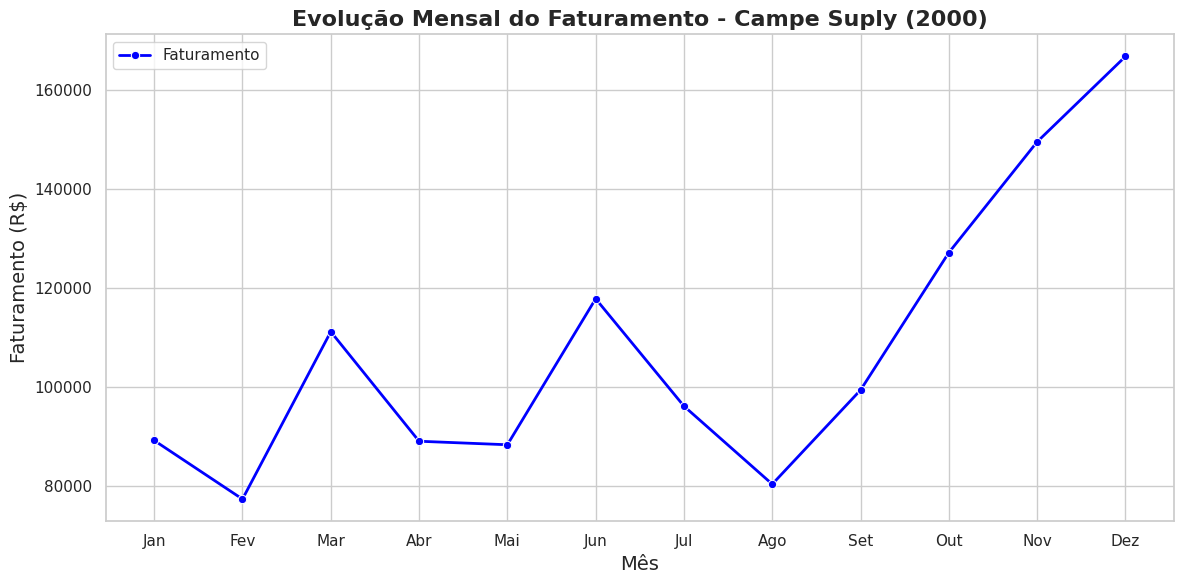

In [9]:
# 1. Plote o gráfico de linha da evolução mensal do faturamento
# Seu código aqui:

vendas_mes = df.groupby('mes')[['faturamento', 'lucro']].sum().reset_index()
plt.figure(figsize=(12, 6))
sns.lineplot(data=vendas_mes, x='mes', y='faturamento', marker='o', linewidth=2,color='blue', label='Faturamento')


plt.title('Evolução Mensal do Faturamento - Campe Suply (2000)', fontsize=16, fontweight='bold')
plt.xlabel('Mês', fontsize=14)
plt.ylabel('Faturamento (R$)', fontsize=14)
plt.xticks(range(1, 13), ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez',],)

plt.tight_layout()
plt.show()

## 🎯 Missão 2: Gráfico de Barras Horizontais — Ranking de Vendedores
Agrupe o faturamento (ou lucro) total por `vendedor`, ordene do maior para o menor e crie um gráfico de barras horizontais (`sns.barplot(x=..., y=...)`).

* **Desafio Bônus:** Tente colocar os valores em `R$` escritos na ponta de cada barra usando `ax.bar_label()`!

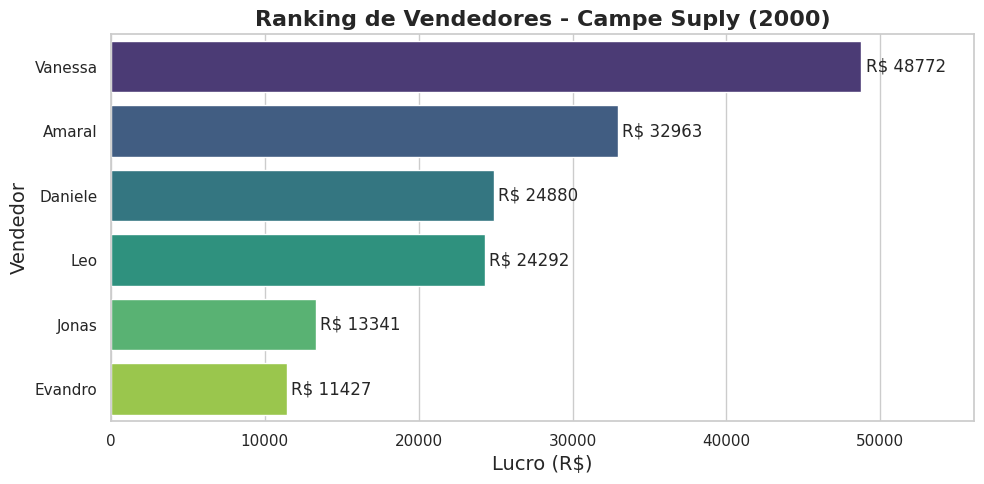

In [25]:
# 2. Plote o ranking de vendedores em barras horizontais
# Seu código aqui:
rank_vend = df.groupby('vendedor')['lucro'].sum().sort_values(ascending=False).reset_index()
ax = sns.barplot(data=rank_vend, x='lucro', y='vendedor', hue = 'vendedor', palette='viridis', legend=False)

plt.title('Ranking de Vendedores - Campe Suply (2000)', fontsize=16, fontweight='bold')
plt.xlabel('Lucro (R$)', fontsize=14)
plt.ylabel('Vendedor', fontsize=14)


for container in ax.containers:
    ax.bar_label(container, fmt = "R$ %0.f", padding=3)

plt.xlim(0, rank_vend['lucro'].max()*1.15)
plt.tight_layout()
plt.show()


## 🎯 Missão 3: Boxplot — Distribuição do Ticket por Setor
Plote um Boxplot (`sns.boxplot`) cruzando `setor` no eixo X e `faturamento` no eixo Y.

* 🧠 **Reflexão:** Observe os pontos acima do limite superior (*outliers* reais de vendas altas no fim do ano). O que teria acontecido com esse gráfico se não tivéssemos limpado aquele erro de digitação de R$ 8.581,60 na Aula 03?

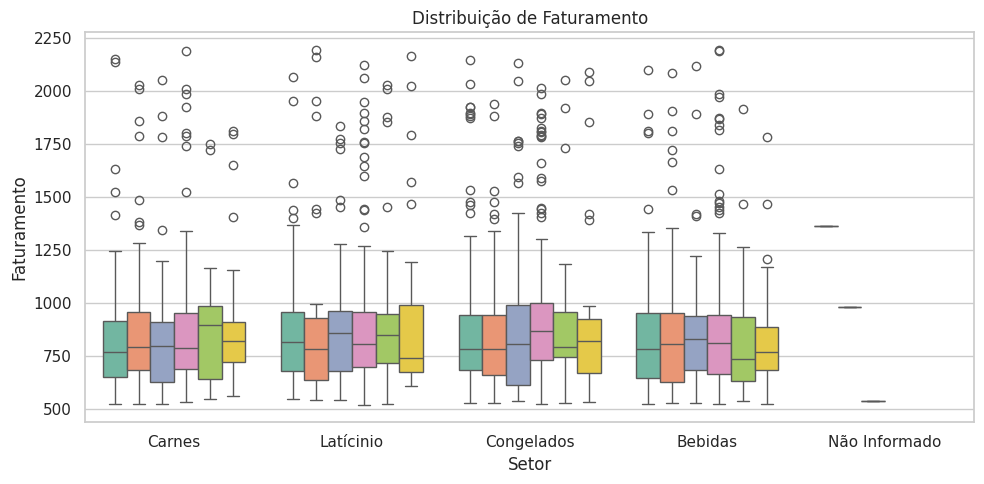

In [29]:
# 3. Plote o Boxplot de faturamento por setor
# Seu código aqui:


plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='setor', y = 'faturamento', hue='vendedor', palette="Set2", legend=False)

plt.title("Distribuição de Faturamento", fontsize=12)
plt.xlabel('Setor', fontsize = 12)
plt.ylabel('Faturamento', fontsize =12)
plt.tight_layout()
plt.show()


## 🎯 Missão 4: Mapa de Calor (Heatmap) — Estado vs. Canal de Cliente
Crie uma `pivot_table` com a soma de `faturamento` tendo `estado` nas linhas e `cliente` nas colunas, e plote um Mapa de Calor com `sns.heatmap(..., annot=True, fmt='.0f', cmap='YlGnBu')`.

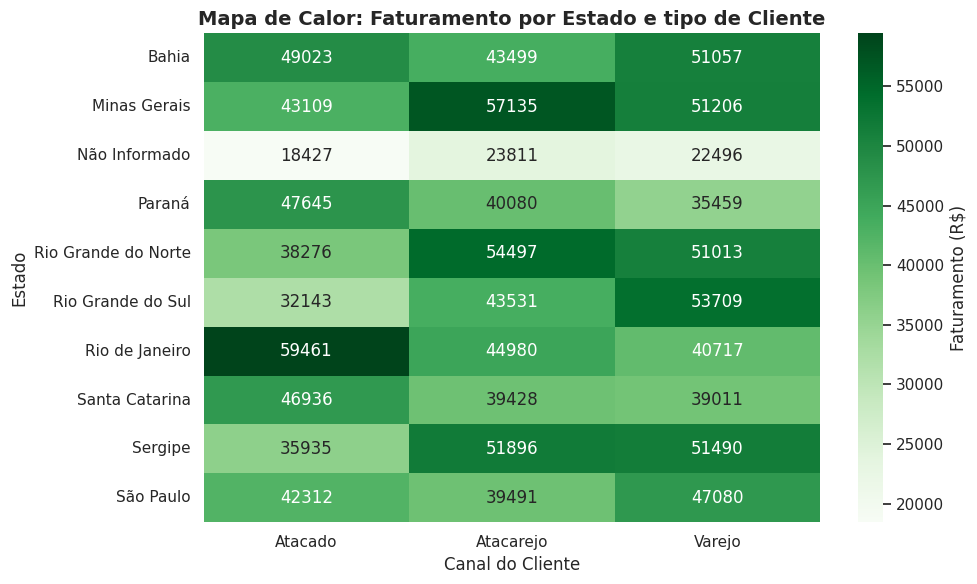

In [35]:
# 4. Plote o Heatmap de Estado x Canal de Cliente
# Seu código aqui:


matriz_estado_cliente = pd.pivot_table(df, values='faturamento', index = 'estado', columns='cliente', aggfunc='sum')

plt.figure(figsize=(10,6))
sns.heatmap(matriz_estado_cliente, annot=True, fmt='.0f', cmap = 'Greens', cbar_kws={'label': 'Faturamento (R$)'},)

plt.title("Mapa de Calor: Faturamento por Estado e tipo de Cliente", fontsize=14,fontweight='bold',)

plt.xlabel('Canal do Cliente', fontsize=12)
plt.ylabel('Estado', fontsize=12)
plt.tight_layout()
plt.show()
